<a href="https://colab.research.google.com/github/JeffinGeorgePalathingal/Retail-Sales-Time-Series-Forecasting/blob/main/Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from prophet import Prophet
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)

#Loading and Inspecting the Dataset

In [4]:
file_url = "https://raw.githubusercontent.com/JeffinGeorgePalathingal/Retail-Sales-Time-Series-Forecasting/main/retail_store_inventory.csv"

df = pd.read_csv(file_url)

df.head()


,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,20,Rainy,0,29.69,Autumn
1,2022-01-01,S001,P0002,Toys,South,204,150,66,144.04,63.01,20,Sunny,0,66.16,Autumn
2,2022-01-01,S001,P0003,Toys,West,102,65,51,74.02,27.99,10,Sunny,1,31.32,Summer
3,2022-01-01,S001,P0004,Toys,North,469,61,164,62.18,32.72,10,Cloudy,1,34.74,Autumn
4,2022-01-01,S001,P0005,Electronics,East,166,14,135,9.26,73.64,0,Sunny,0,68.95,Summer


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 73100 entries, 0 to 73099
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Date                73100 non-null  object 
 1   Store ID            73100 non-null  object 
 2   Product ID          73100 non-null  object 
 3   Category            73100 non-null  object 
 4   Region              73100 non-null  object 
 5   Inventory Level     73100 non-null  int64  
 6   Units Sold          73100 non-null  int64  
 7   Units Ordered       73100 non-null  int64  
 8   Demand Forecast     73100 non-null  float64
 9   Price               73100 non-null  float64
 10  Discount            73100 non-null  int64  
 11  Weather Condition   73100 non-null  object 
 12  Holiday/Promotion   73100 non-null  int64  
 13  Competitor Pricing  73100 non-null  float64
 14  Seasonality         73100 non-null  object 
dtypes: float64(3), int64(5), object(7)
memory usage: 8.4+

In [6]:
# Inspecting the Date column
print("Data type:", df['Date'].dtype)
print("Unique dates:", df['Date'].nunique())
print("Minimum date:", df['Date'].min())
print("Maximum date:", df['Date'].max())

print("\nFirst 10 dates:")
print(df['Date'].head(10).to_list())

print("\nLast 10 dates:")
print(df['Date'].tail(10).to_list())

Data type: object
Unique dates: 731
Minimum date: 2022-01-01
Maximum date: 2024-01-01

First 10 dates:
['2022-01-01', '2022-01-01', '2022-01-01', '2022-01-01', '2022-01-01', '2022-01-01', '2022-01-01', '2022-01-01', '2022-01-01', '2022-01-01']

Last 10 dates:
['2024-01-01', '2024-01-01', '2024-01-01', '2024-01-01', '2024-01-01', '2024-01-01', '2024-01-01', '2024-01-01', '2024-01-01', '2024-01-01']


In [7]:
# Check whether every calendar date is present

df['Date'] = pd.to_datetime(df['Date'])
expected_dates = pd.date_range(
    start=df['Date'].min(),
    end=df['Date'].max(),
    freq='D'
)

missing_dates = expected_dates.difference(df['Date'].unique())

print("Expected dates:", len(expected_dates))
print("Actual unique dates:", df['Date'].nunique())
print("Missing dates:", len(missing_dates))

if len(missing_dates) > 0:
    print("\nMissing dates:")
    print(missing_dates)

Expected dates: 731
Actual unique dates: 731
Missing dates: 0


In [8]:
# Inspect Store ID
print("Data type:", df['Store ID'].dtype)
print("Unique stores:", df['Store ID'].nunique())

print("\nStore IDs:")
print(df['Store ID'].unique())

print("\nObservations per store:")
print(df['Store ID'].value_counts().sort_index())

Data type: object
Unique stores: 5

Store IDs:
['S001' 'S002' 'S003' 'S004' 'S005']

Observations per store:
Store ID
S001    14620
S002    14620
S003    14620
S004    14620
S005    14620
Name: count, dtype: int64


In [9]:
# Product ID
print("Data type:", df['Product ID'].dtype)
print("Unique products:", df['Product ID'].nunique())

print("\nProduct IDs:")
print(df['Product ID'].unique())

print("\nObservations per product:")
print(df['Product ID'].value_counts().sort_index())

Data type: object
Unique products: 20

Product IDs:
['P0001' 'P0002' 'P0003' 'P0004' 'P0005' 'P0006' 'P0007' 'P0008' 'P0009'
 'P0010' 'P0011' 'P0012' 'P0013' 'P0014' 'P0015' 'P0016' 'P0017' 'P0018'
 'P0019' 'P0020']

Observations per product:
Product ID
P0001    3655
P0002    3655
P0003    3655
P0004    3655
P0005    3655
P0006    3655
P0007    3655
P0008    3655
P0009    3655
P0010    3655
P0011    3655
P0012    3655
P0013    3655
P0014    3655
P0015    3655
P0016    3655
P0017    3655
P0018    3655
P0019    3655
P0020    3655
Name: count, dtype: int64


In [10]:
# Product distribution across stores
product_store = pd.crosstab(df['Product ID'], df['Store ID'])

print(product_store)

Store ID    S001  S002  S003  S004  S005
Product ID                              
P0001        731   731   731   731   731
P0002        731   731   731   731   731
P0003        731   731   731   731   731
P0004        731   731   731   731   731
P0005        731   731   731   731   731
P0006        731   731   731   731   731
P0007        731   731   731   731   731
P0008        731   731   731   731   731
P0009        731   731   731   731   731
P0010        731   731   731   731   731
P0011        731   731   731   731   731
P0012        731   731   731   731   731
P0013        731   731   731   731   731
P0014        731   731   731   731   731
P0015        731   731   731   731   731
P0016        731   731   731   731   731
P0017        731   731   731   731   731
P0018        731   731   731   731   731
P0019        731   731   731   731   731
P0020        731   731   731   731   731


In [11]:
# Inspecting Category Column

print("Data type:", df['Category'].dtype)
print("Unique categories:", df['Category'].nunique())

print("\nCategories:")
print(df['Category'].unique())

print("\nObservations per category:")
print(df['Category'].value_counts())

Data type: object
Unique categories: 5

Categories:
['Groceries' 'Toys' 'Electronics' 'Furniture' 'Clothing']

Observations per category:
Category
Furniture      14699
Toys           14643
Clothing       14626
Groceries      14611
Electronics    14521
Name: count, dtype: int64


In [12]:
# Product-to-category mapping
product_category = df.groupby('Product ID')['Category'].nunique()

print("Number of categories assigned to each product:")
print(product_category.value_counts())

print("\nProduct-category combinations:")
print(df[['Product ID', 'Category']].drop_duplicates().sort_values('Product ID'))

Number of categories assigned to each product:
Category
5    20
Name: count, dtype: int64

Product-category combinations:
    Product ID     Category
0        P0001    Groceries
120      P0001  Electronics
40       P0001         Toys
240      P0001     Clothing
340      P0001    Furniture
..         ...          ...
79       P0020     Clothing
59       P0020  Electronics
239      P0020    Groceries
19       P0020         Toys
339      P0020    Furniture

[100 rows x 2 columns]


In [13]:
# Product-Category-Store combinations
product_category_store = (
    df.groupby(['Store ID', 'Product ID'])['Category']
      .nunique()
      .unstack()
)

print(product_category_store)

Product ID  P0001  P0002  P0003  P0004  P0005  P0006  P0007  P0008  P0009  \
Store ID                                                                    
S001            5      5      5      5      5      5      5      5      5   
S002            5      5      5      5      5      5      5      5      5   
S003            5      5      5      5      5      5      5      5      5   
S004            5      5      5      5      5      5      5      5      5   
S005            5      5      5      5      5      5      5      5      5   

Product ID  P0010  P0011  P0012  P0013  P0014  P0015  P0016  P0017  P0018  \
Store ID                                                                    
S001            5      5      5      5      5      5      5      5      5   
S002            5      5      5      5      5      5      5      5      5   
S003            5      5      5      5      5      5      5      5      5   
S004            5      5      5      5      5      5      5      5      5  

In [14]:
# Number of unique Category assignments for each Store-Product combination
check = (
    df.groupby(['Store ID', 'Product ID'])['Category']
      .nunique()
)

print(check.value_counts().sort_index())

Category
5    100
Name: count, dtype: int64


Category assignments were inconsistent across products, so the Category variable was excluded from further analysis.

In [15]:
df = df.drop(columns=['Category'])

In [16]:
# Inspecting Regions

print("Data type:", df['Region'].dtype)
print("Unique regions:", df['Region'].nunique())

print("\nRegions:")
print(df['Region'].unique())

print("\nObservations per region:")
print(df['Region'].value_counts())

Data type: object
Unique regions: 4

Regions:
['North' 'South' 'West' 'East']

Observations per region:
Region
East     18349
South    18297
North    18228
West     18226
Name: count, dtype: int64


In [17]:
# Inspecting Units sold
print(df['Units Sold'].describe())


count    73100.000000
mean       136.464870
std        108.919406
min          0.000000
25%         49.000000
50%        107.000000
75%        203.000000
max        499.000000
Name: Units Sold, dtype: float64


In [18]:
# Check whether Units Sold exceeds Inventory Level
sales_exceed_inventory = df['Units Sold'] > df['Inventory Level']

print("Rows where Units Sold > Inventory Level:", sales_exceed_inventory.sum())
print("Percentage of rows:", sales_exceed_inventory.mean() * 100, "%")

Rows where Units Sold > Inventory Level: 0
Percentage of rows: 0.0 %


In [19]:
#Remaining numerical features
numerical_features = [
    'Demand Forecast',
    'Price',
    'Discount',
    'Holiday/Promotion',
    'Competitor Pricing'
]

print(df[numerical_features].describe())

       Demand Forecast         Price      Discount  Holiday/Promotion  \
count     73100.000000  73100.000000  73100.000000       73100.000000   
mean        141.494720     55.135108     10.009508           0.497305   
std         109.254076     26.021945      7.083746           0.499996   
min          -9.990000     10.000000      0.000000           0.000000   
25%          53.670000     32.650000      5.000000           0.000000   
50%         113.015000     55.050000     10.000000           0.000000   
75%         208.052500     77.860000     15.000000           1.000000   
max         518.550000    100.000000     20.000000           1.000000   

       Competitor Pricing  
count        73100.000000  
mean            55.146077  
std             26.191408  
min              5.030000  
25%             32.680000  
50%             55.010000  
75%             77.820000  
max            104.940000  


In [20]:
# Price difference relative to competitor
df['Price Difference'] = df['Competitor Pricing'] - df['Price']

print(df['Price Difference'].describe())

count    73100.000000
mean         0.010969
std          2.888538
min         -5.000000
25%         -2.500000
50%          0.000000
75%          2.530000
max          5.000000
Name: Price Difference, dtype: float64


In [21]:
# Inspecting Holiday/Promotion distribution

print("\nHoliday/Promotion value counts:")
print(df['Holiday/Promotion'].value_counts())

print("\nHoliday/Promotion percentage:")
print(df['Holiday/Promotion'].value_counts(normalize=True) * 100)


Holiday/Promotion value counts:
Holiday/Promotion
0    36747
1    36353
Name: count, dtype: int64

Holiday/Promotion percentage:
Holiday/Promotion
0    50.269494
1    49.730506
Name: proportion, dtype: float64


In [22]:
# Check Weather Condition and Seasonality consistency by date

date_category_check = (
    df.groupby('Date')[['Weather Condition', 'Seasonality']]
      .nunique()
)

print("Dates with multiple Weather Conditions:")
print((date_category_check['Weather Condition'] > 1).sum())

print("\nDates with multiple Seasonality values:")
print((date_category_check['Seasonality'] > 1).sum())

Dates with multiple Weather Conditions:
731

Dates with multiple Seasonality values:
731


In [23]:
# Inspecting Weather Condition and Seasonality categories

print("Weather Conditions:")
print(df['Weather Condition'].unique())

print("\nSeasonality:")
print(df['Seasonality'].unique())

Weather Conditions:
['Rainy' 'Sunny' 'Cloudy' 'Snowy']

Seasonality:
['Autumn' 'Summer' 'Winter' 'Spring']


In [24]:
date_weather_season = (
    df[['Date', 'Weather Condition', 'Seasonality']]
    .drop_duplicates()
    .sort_values('Date')
)

date_weather_season.head(20)

,Date,Weather Condition,Seasonality
0,2022-01-01,Rainy,Autumn
45,2022-01-01,Rainy,Summer
35,2022-01-01,Rainy,Spring
33,2022-01-01,Cloudy,Summer
30,2022-01-01,Snowy,Autumn
18,2022-01-01,Cloudy,Winter
14,2022-01-01,Snowy,Winter
11,2022-01-01,Snowy,Spring
27,2022-01-01,Snowy,Summer
7,2022-01-01,Cloudy,Spring


In [25]:
# Checking zero-sales observations

print("Zero sales:", (df['Units Sold'] == 0).sum())
print("Zero sales %:", (df['Units Sold'] == 0).mean() * 100)

print("Unique values:", df['Units Sold'].nunique())

Zero sales: 360
Zero sales %: 0.49247606019151846
Unique values: 498


#Exploratory Data Analysis

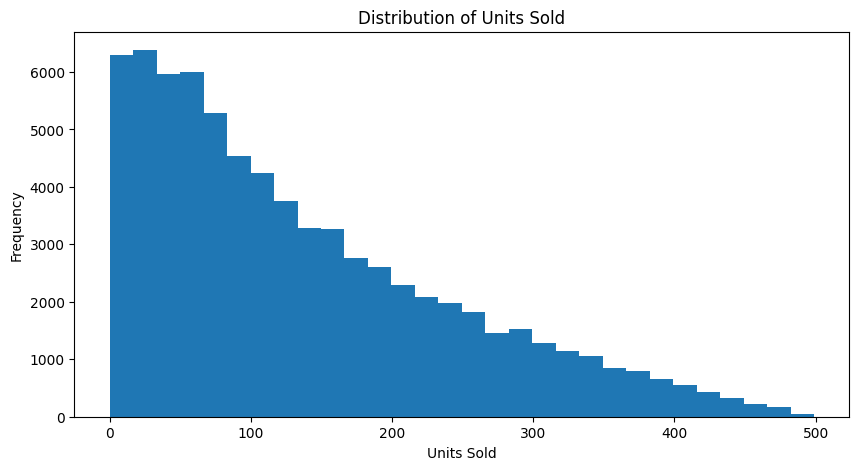

In [26]:
# Distribution of Units Sold
plt.figure(figsize=(10, 5))
plt.hist(df['Units Sold'], bins=30)
plt.xlabel('Units Sold')
plt.ylabel('Frequency')
plt.title('Distribution of Units Sold')
plt.show()

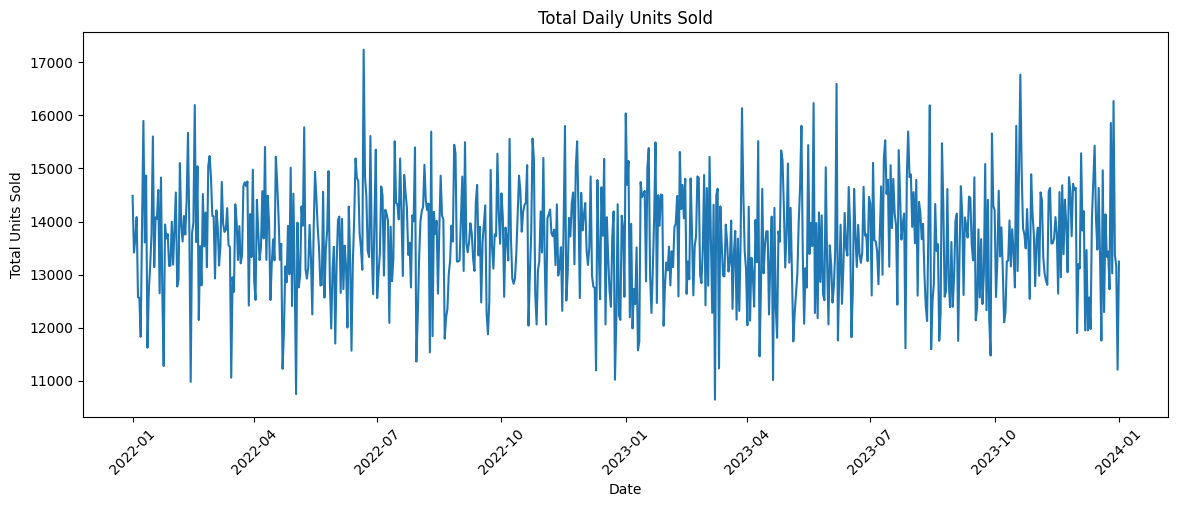

In [27]:
# Aggregate Total Daily Sales

daily_sales = df.groupby('Date')['Units Sold'].sum()

plt.figure(figsize=(14, 5))
plt.plot(daily_sales)
plt.xlabel('Date')
plt.ylabel('Total Units Sold')
plt.title('Total Daily Units Sold')
plt.xticks(rotation=45)
plt.show()

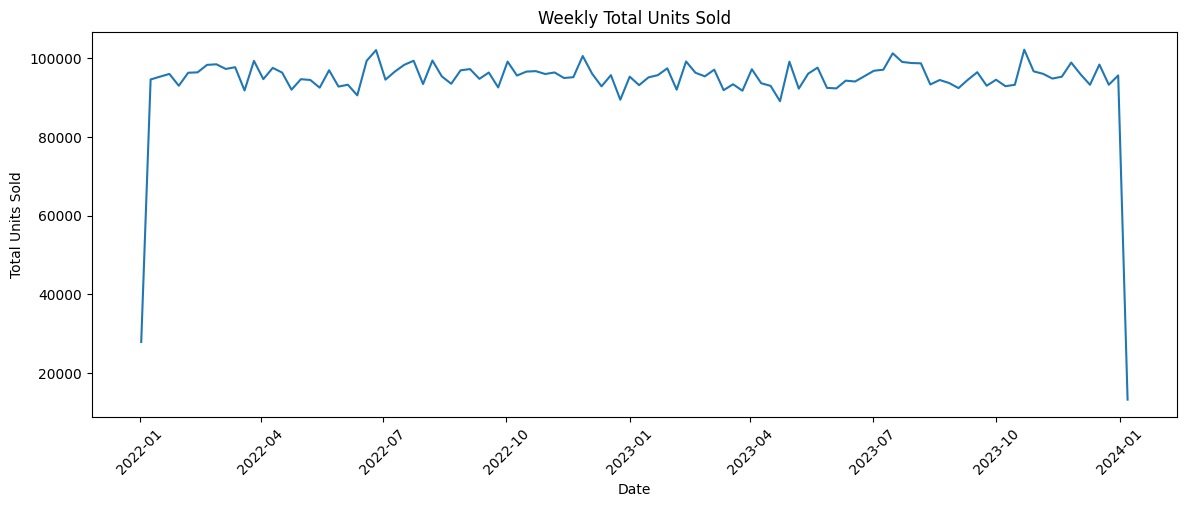

In [28]:
# Aggregate Weekly Sales

weekly_sales = daily_sales.resample('W').sum()

plt.figure(figsize=(14, 5))
plt.plot(weekly_sales)
plt.xlabel('Date')
plt.ylabel('Total Units Sold')
plt.title('Weekly Total Units Sold')
plt.xticks(rotation=45)
plt.show()

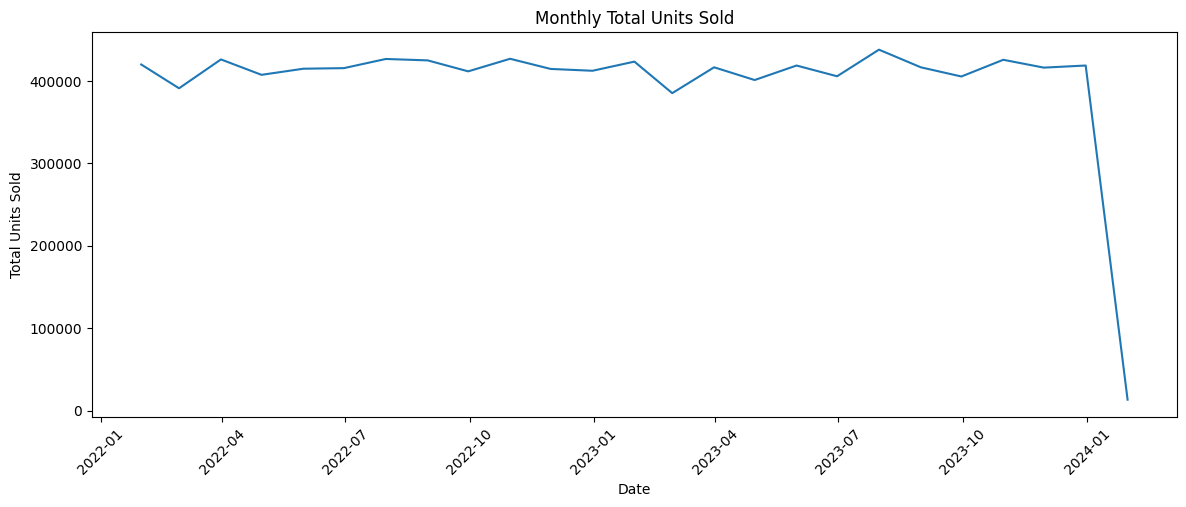

In [29]:
# Aggregate Monthly Sales

monthly_sales = daily_sales.resample('ME').sum()

plt.figure(figsize=(14, 5))
plt.plot(monthly_sales)
plt.xlabel('Date')
plt.ylabel('Total Units Sold')
plt.title('Monthly Total Units Sold')
plt.xticks(rotation=45)
plt.show()

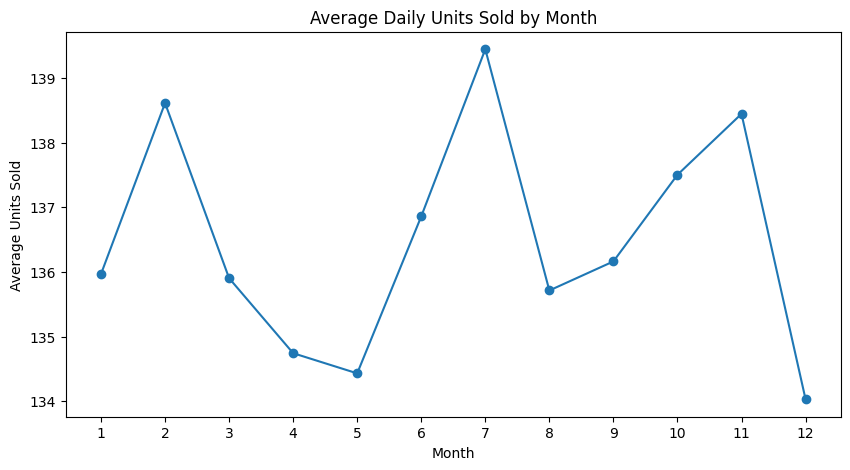

In [30]:
monthly_pattern = df.groupby(df['Date'].dt.month)['Units Sold'].mean()

plt.figure(figsize=(10, 5))
plt.plot(monthly_pattern.index, monthly_pattern.values, marker='o')
plt.xlabel('Month')
plt.ylabel('Average Units Sold')
plt.title('Average Daily Units Sold by Month')
plt.xticks(range(1, 13))
plt.show()

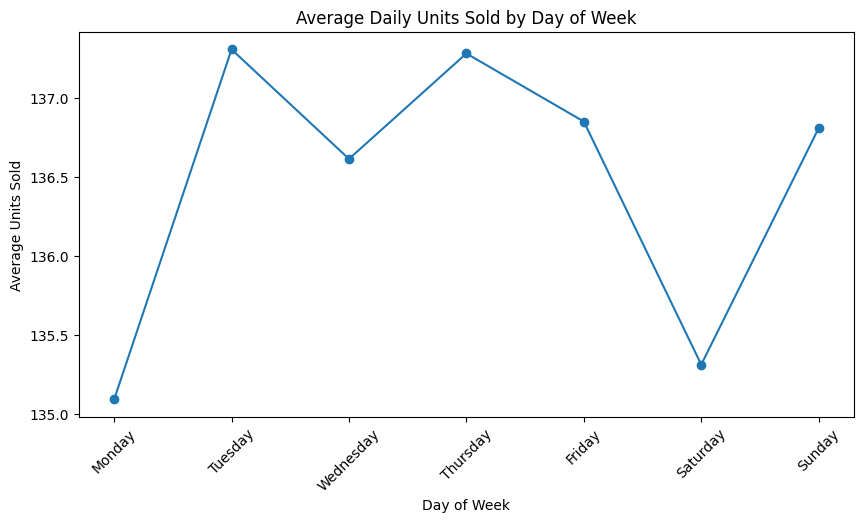

In [31]:
weekday_pattern = df.groupby(df['Date'].dt.dayofweek)['Units Sold'].mean()

plt.figure(figsize=(10, 5))
plt.plot(weekday_pattern.index, weekday_pattern.values, marker='o')
plt.xlabel('Day of Week')
plt.ylabel('Average Units Sold')
plt.title('Average Daily Units Sold by Day of Week')
plt.xticks(
    range(7),
    ['Monday', 'Tuesday', 'Wednesday', 'Thursday',
     'Friday', 'Saturday', 'Sunday'],
    rotation=45
)
plt.show()

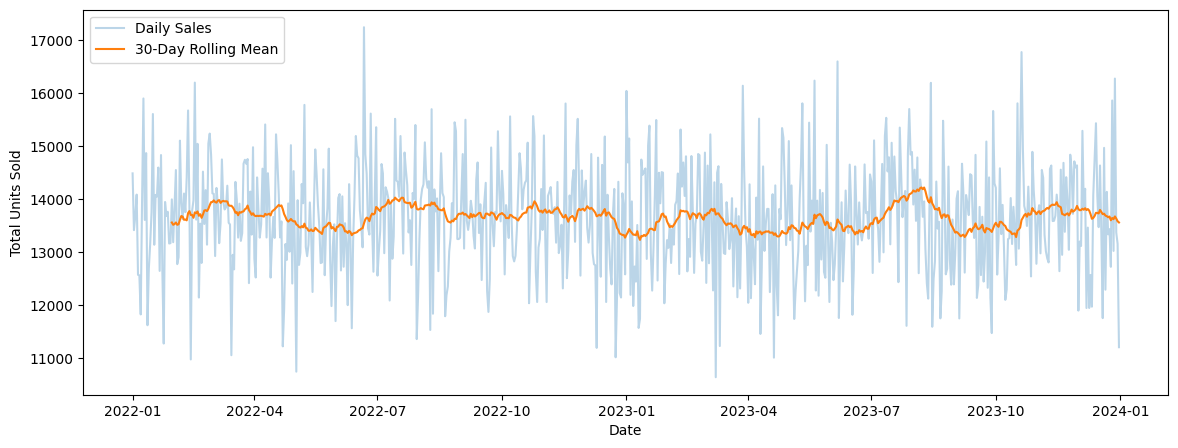

In [32]:
eda_df = df[df['Date'] < '2024-01-01'].copy()

daily_sales_eda = (
    eda_df.groupby('Date')['Units Sold']
    .sum()
    .sort_index()
)

rolling_30 = daily_sales_eda.rolling(30).mean()

plt.figure(figsize=(14, 5))
plt.plot(daily_sales_eda, alpha=0.3, label='Daily Sales')
plt.plot(rolling_30, label='30-Day Rolling Mean')
plt.xlabel('Date')
plt.ylabel('Total Units Sold')
#plt.title('Daily Sales with 30-Day Rolling Mean')
plt.legend()
plt.show()

In [33]:
store_sales = df.groupby('Store ID')['Units Sold'].agg(['sum', 'mean', 'std'])

store_sales

,sum,mean,std
Store ID,,,
S001,1975750,135.140219,108.708785
S002,1987715,135.958618,108.933513
S003,2022696,138.351300,109.776069
S004,1979245,135.379275,107.639338
S005,2010176,137.494938,109.505703


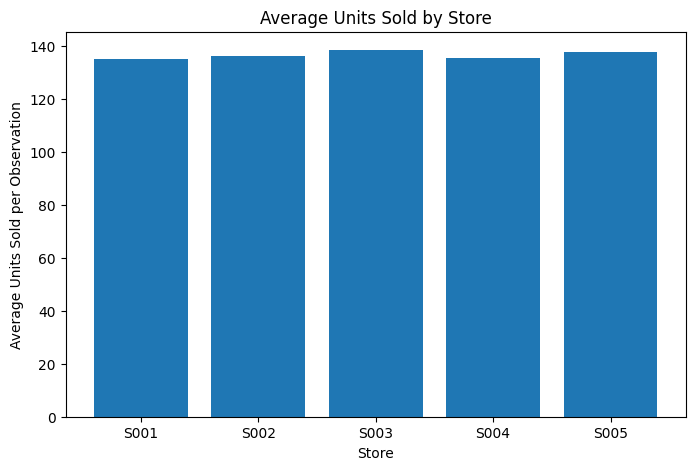

In [34]:
plt.figure(figsize=(8, 5))
plt.bar(store_sales.index, store_sales['mean'])
plt.xlabel('Store')
plt.ylabel('Average Units Sold per Observation')
plt.title('Average Units Sold by Store')
plt.show()

In [35]:
product_sales = df.groupby('Product ID')['Units Sold'].agg(['sum', 'mean', 'std'])

product_sales.sort_values('mean', ascending=False)

,sum,mean,std
Product ID,,,
P0016,508472,139.116826,109.389823
P0020,507708,138.907798,110.229782
P0014,507622,138.884268,110.203837
P0015,507283,138.791518,109.914956
P0005,503648,137.796990,106.854998
P0009,502086,137.369631,110.560806
P0013,500619,136.968263,108.149168
P0017,500510,136.938440,107.890733
P0011,499362,136.624350,108.245989


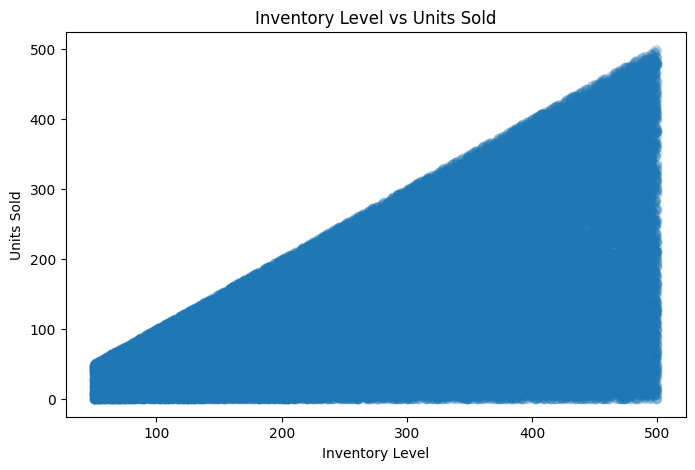

In [36]:
plt.figure(figsize=(8, 5))
plt.scatter(
    df['Inventory Level'],
    df['Units Sold'],
    alpha=0.15
)
plt.xlabel('Inventory Level')
plt.ylabel('Units Sold')
plt.title('Inventory Level vs Units Sold')
plt.show()

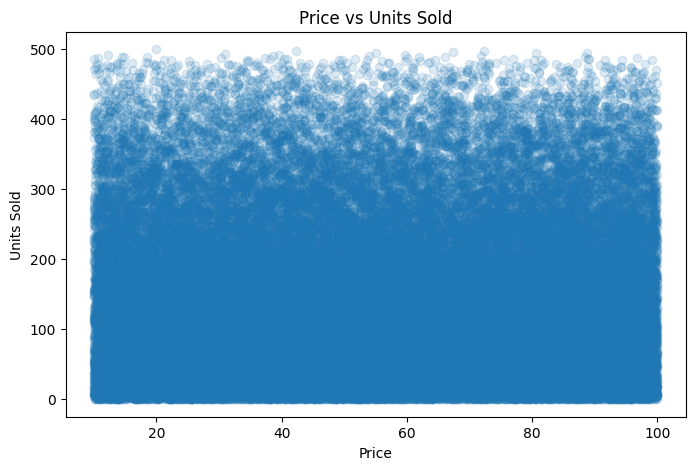

In [37]:
plt.figure(figsize=(8, 5))
plt.scatter(
    df['Price'],
    df['Units Sold'],
    alpha=0.15
)
plt.xlabel('Price')
plt.ylabel('Units Sold')
plt.title('Price vs Units Sold')
plt.show()

In [38]:
holiday_sales = df.groupby('Holiday/Promotion')['Units Sold'].agg(['mean', 'median', 'std', 'count'])

holiday_sales

,mean,median,std,count
Holiday/Promotion,,,,
0,136.505375,107.0,109.276450,36747
1,136.423926,108.0,108.558786,36353


<Figure size 800x500 with 0 Axes>

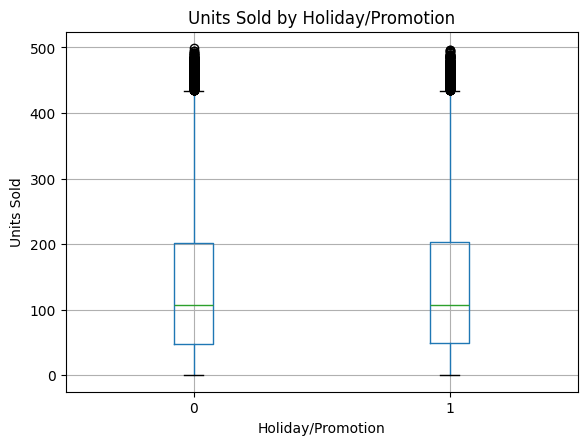

In [39]:
plt.figure(figsize=(8, 5))

df.boxplot(
    column='Units Sold',
    by='Holiday/Promotion'
)

plt.title('Units Sold by Holiday/Promotion')
plt.suptitle('')
plt.xlabel('Holiday/Promotion')
plt.ylabel('Units Sold')
plt.show()

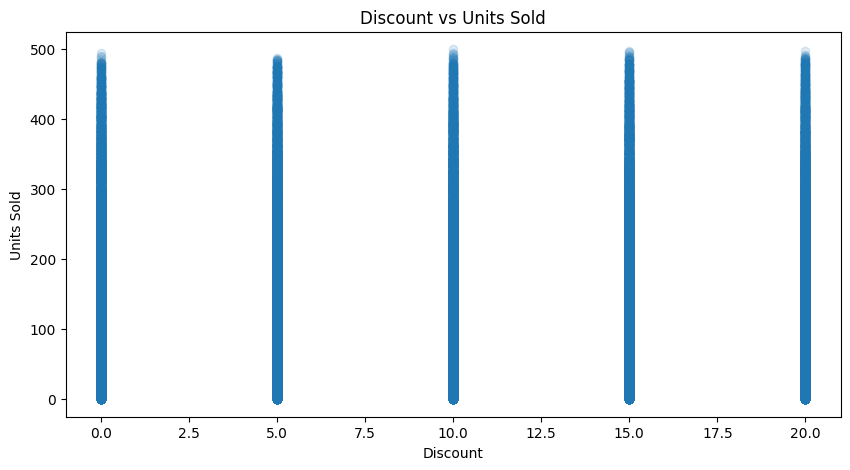

In [40]:
plt.figure(figsize=(10, 5))

plt.scatter(
    df['Discount'],
    df['Units Sold'],
    alpha=0.15
)

plt.xlabel('Discount')
plt.ylabel('Units Sold')
plt.title('Discount vs Units Sold')
plt.show()

<Figure size 900x500 with 0 Axes>

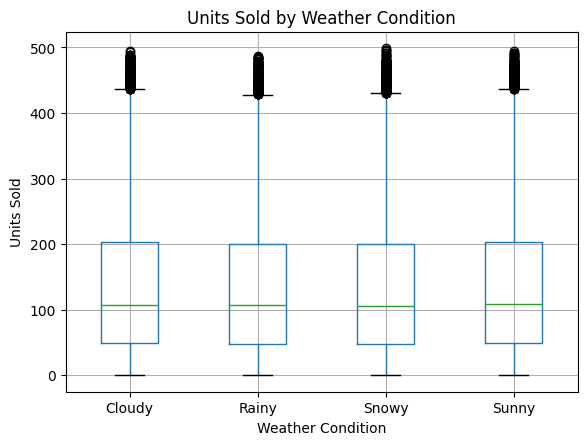

In [41]:
plt.figure(figsize=(9, 5))

df.boxplot(
    column='Units Sold',
    by='Weather Condition'
)

plt.title('Units Sold by Weather Condition')
plt.suptitle('')
plt.xlabel('Weather Condition')
plt.ylabel('Units Sold')
plt.show()

In [42]:
season_sales = df.groupby('Seasonality')['Units Sold'].agg(
    ['mean', 'median', 'std', 'count']
)

season_sales

,mean,median,std,count
Seasonality,,,,
Autumn,137.782444,110.0,109.103465,18193
Spring,135.826828,107.0,108.852691,18317
Summer,135.428298,106.0,108.881508,18305
Winter,136.830790,108.0,108.834411,18285


<Figure size 900x500 with 0 Axes>

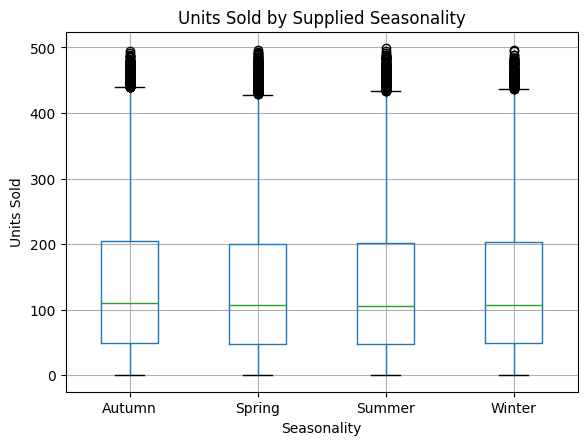

In [43]:
plt.figure(figsize=(9, 5))

df.boxplot(
    column='Units Sold',
    by='Seasonality'
)

plt.title('Units Sold by Supplied Seasonality')
plt.suptitle('')
plt.xlabel('Seasonality')
plt.ylabel('Units Sold')
plt.show()

In [44]:
df[['Price Difference', 'Units Sold']].corr()

,Price Difference,Units Sold
Price Difference,1.000000,0.001674
Units Sold,0.001674,1.000000


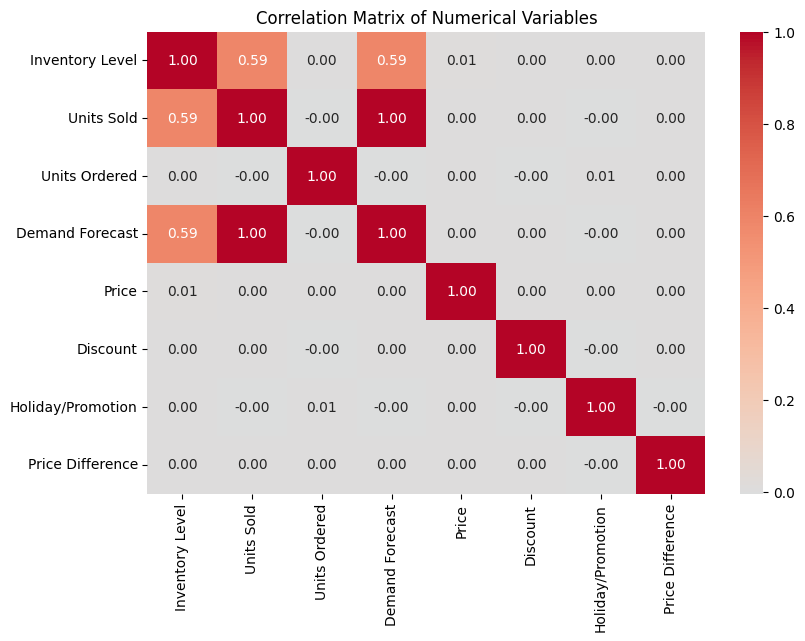

In [45]:
# Correlation matrix for numerical variables


corr_matrix = df[
    [
        'Inventory Level',
        'Units Sold',
        'Units Ordered',
        'Demand Forecast',
        'Price',
        'Discount',
        'Holiday/Promotion',
        'Price Difference'
    ]
].corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('Correlation Matrix of Numerical Variables')
plt.show()


#Time Series Diagnostics

In [46]:
# Aggregate daily Units Sold for the modelling period

ts = (
    df[df['Date'] < '2024-01-01']
    .groupby('Date')['Units Sold']
    .sum()
    .sort_index()
)

ts.head()

,Units Sold
Date,
2022-01-01,14484
2022-01-02,13415
2022-01-03,13681
2022-01-04,14084
2022-01-05,12572


In [47]:
print("Number of observations:", len(ts))
print("Start:", ts.index.min())
print("End:", ts.index.max())

Number of observations: 730
Start: 2022-01-01 00:00:00
End: 2023-12-31 00:00:00


<Figure size 1200x500 with 0 Axes>

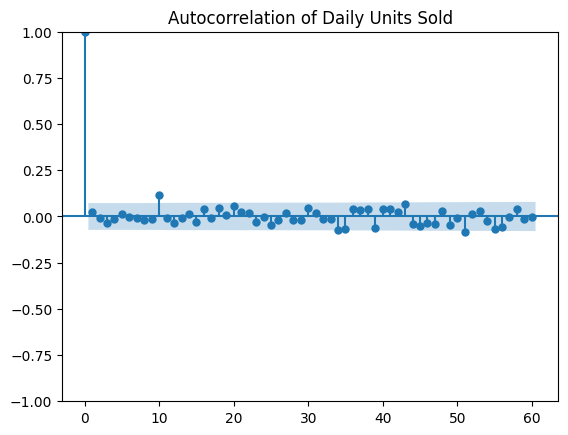

In [48]:


plt.figure(figsize=(12, 5))
plot_acf(ts, lags=60)
plt.title('Autocorrelation of Daily Units Sold')
plt.show()

<Figure size 1200x500 with 0 Axes>

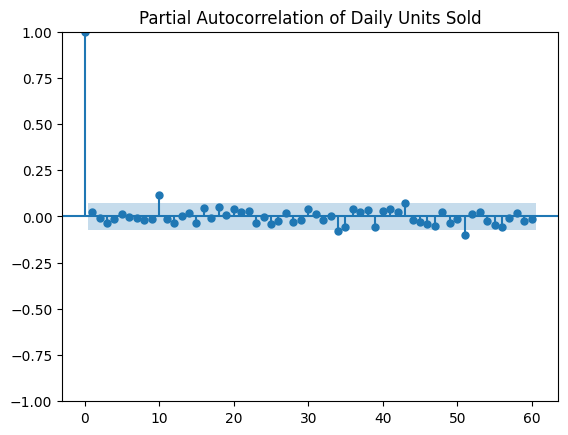

In [49]:


plt.figure(figsize=(12, 5))
plot_pacf(ts, lags=60, method='ywm')
plt.title('Partial Autocorrelation of Daily Units Sold')
plt.show()

In [50]:
# ADF test for stationarity

adf_result = adfuller(ts, result_object=False)

print("ADF Statistic:", adf_result[0])
print("p-value:", adf_result[1])

print("\nCritical Values:")
for key, value in adf_result[4].items():
    print(f"{key}: {value}")

ADF Statistic: -26.2916078960034
p-value: 0.0

Critical Values:
1%: -3.4393520240470554
5%: -2.8655128165959236
10%: -2.5688855736949163


#Train-Test Split

In [51]:
ts = ts.asfreq('D')

train_size = int(len(ts) * 0.8)

train = ts.iloc[:train_size]
test = ts.iloc[train_size:]

print("Train:", len(train))
print("Test:", len(test))

Train: 584
Test: 146


#ARIMA

In [52]:
orders = [
    (0, 0, 0),
    (1, 0, 0),
    (0, 0, 1),
    (1, 0, 1)
]

models = {}

for order in orders:
    model = ARIMA(train, order=order)
    result = model.fit()
    models[order] = result

    print(f"ARIMA{order} → AIC: {result.aic:.2f}, BIC: {result.bic:.2f}")

ARIMA(0, 0, 0) → AIC: 9759.92, BIC: 9768.66
ARIMA(1, 0, 0) → AIC: 9761.45, BIC: 9774.56
ARIMA(0, 0, 1) → AIC: 9761.46, BIC: 9774.56
ARIMA(1, 0, 1) → AIC: 9763.45, BIC: 9780.93


In [53]:
#Making predictions

predictions = {}

for order, model in models.items():
    predictions[order] = model.forecast(steps=len(test))

In [54]:
#MAE and RMSE


results = []

for order, forecast in predictions.items():
    mae = mean_absolute_error(test, forecast)
    rmse = np.sqrt(mean_squared_error(test, forecast))

    results.append({
        'Model': f'ARIMA{order}',
        'MAE': mae,
        'RMSE': rmse
    })

results_df = pd.DataFrame(results)

results_df.sort_values('RMSE')

,Model,MAE,RMSE
0,"ARIMA(0, 0, 0)",845.689735,1054.165365
1,"ARIMA(1, 0, 0)",845.718900,1054.166208
2,"ARIMA(0, 0, 1)",845.718379,1054.166918
3,"ARIMA(1, 0, 1)",845.715018,1054.168133


Naive Forecasting  Baseline

In [55]:
naive_predictions = test.shift(1)
naive_predictions.iloc[0] = train.iloc[-1]

naive_mae = mean_absolute_error(test, naive_predictions)
naive_rmse = np.sqrt(mean_squared_error(test, naive_predictions))

print("Naive MAE:", naive_mae)
print("Naive RMSE:", naive_rmse)

Naive MAE: 1171.4520547945206
Naive RMSE: 1479.497415590756


In [56]:
results_df = pd.concat([
    results_df,
    pd.DataFrame([{
        'Model': 'Naive',
        'MAE': naive_mae,
        'RMSE': naive_rmse
    }])
], ignore_index=True)

results_df.sort_values('RMSE')

,Model,MAE,RMSE
0,"ARIMA(0, 0, 0)",845.689735,1054.165365
1,"ARIMA(1, 0, 0)",845.718900,1054.166208
2,"ARIMA(0, 0, 1)",845.718379,1054.166918
3,"ARIMA(1, 0, 1)",845.715018,1054.168133
4,Naive,1171.452055,1479.497416


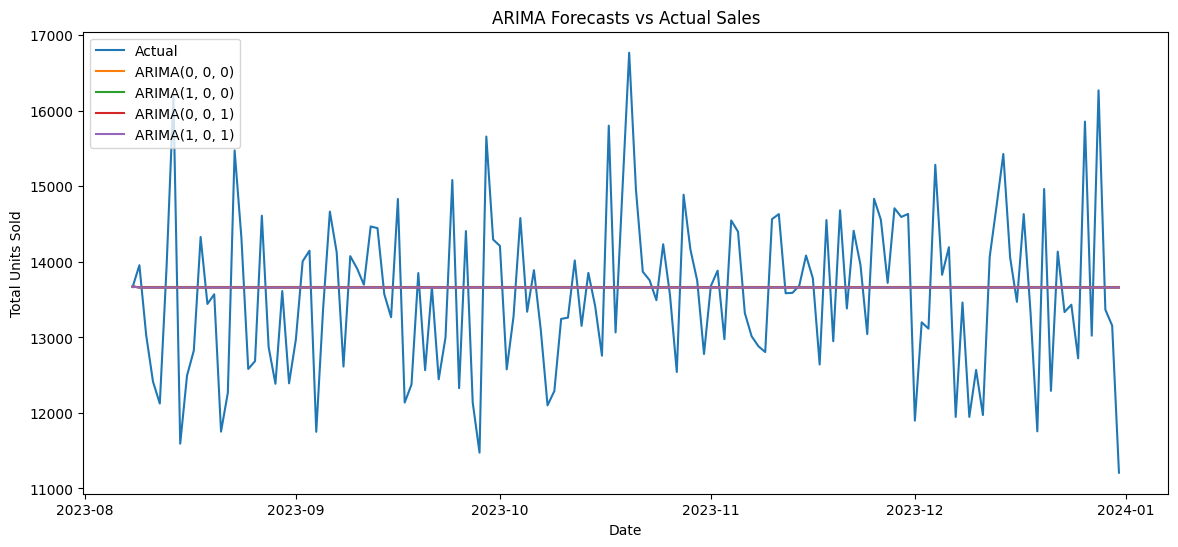

In [57]:
plt.figure(figsize=(14, 6))

plt.plot(test.index, test, label='Actual')

for order, forecast in predictions.items():
    plt.plot(
        test.index,
        forecast,
        label=f'ARIMA{order}'
    )

plt.xlabel('Date')
plt.ylabel('Total Units Sold')
plt.title('ARIMA Forecasts vs Actual Sales')
plt.legend()
plt.show()

#SARIMA

In [58]:
sarima_model = SARIMAX(
    train,
    order=(0, 0, 0),
    seasonal_order=(1, 0, 0, 7)
)

sarima_result = sarima_model.fit(disp=False)

print(sarima_result.summary())

                                SARIMAX Results                                
Dep. Variable:              Units Sold   No. Observations:                  584
Model:             SARIMAX(1, 0, 0, 7)   Log Likelihood               -5095.051
Date:                 Tue, 20 Oct 2026   AIC                          10194.102
Time:                         18:09:33   BIC                          10202.841
Sample:                     01-01-2022   HQIC                         10197.508
                          - 08-07-2023                                         
Covariance Type:                   opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.S.L7        0.9944      0.004    226.993      0.000       0.986       1.003
sigma2      2.101e+06   1.24e+05     16.893      0.000    1.86e+06    2.34e+06
Ljung-Box (L1) (Q):                   1.64  

In [59]:
sarima_predictions = sarima_result.forecast(
    steps=len(test)
)

sarima_predictions.index = test.index

In [60]:
# Evaluate SARIMA forecasts

sarima_mae = mean_absolute_error(test, sarima_predictions)
sarima_rmse = np.sqrt(
    mean_squared_error(test, sarima_predictions)
)

print("SARIMA MAE:", sarima_mae)
print("SARIMA RMSE:", sarima_rmse)

SARIMA MAE: 1152.6425209827116
SARIMA RMSE: 1441.9698466572752


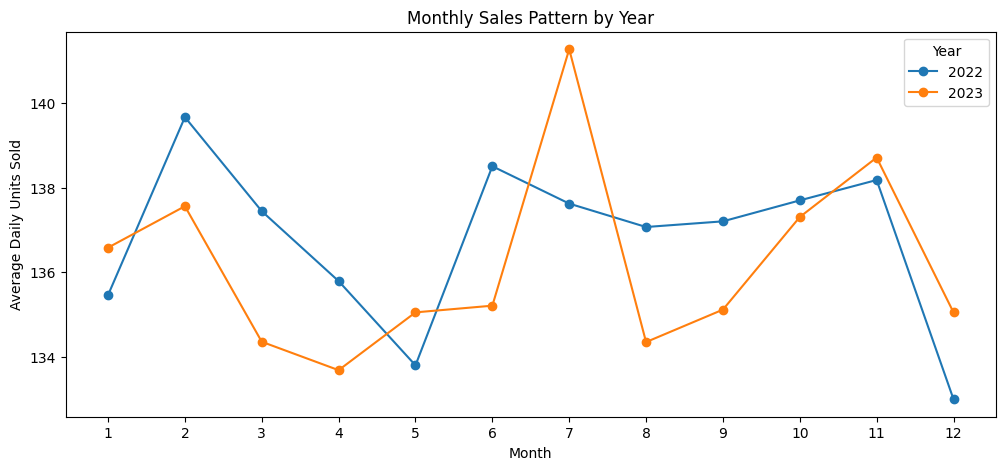

In [61]:
year_month_sales = (
    df[df['Date'] < '2024-01-01']
    .assign(
        Year=df['Date'].dt.year,
        Month=df['Date'].dt.month
    )
    .groupby(['Year', 'Month'])['Units Sold']
    .mean()
    .unstack(0)
)

year_month_sales.plot(figsize=(12, 5), marker='o')

plt.xlabel('Month')
plt.ylabel('Average Daily Units Sold')
plt.title('Monthly Sales Pattern by Year')
plt.xticks(range(1, 13))
plt.legend(title='Year')
plt.show()

#Prophet

In [62]:
prophet_train = train.reset_index()

prophet_train.columns = ['ds', 'y']

prophet_train.head()

,ds,y
0,2022-01-01,14484
1,2022-01-02,13415
2,2022-01-03,13681
3,2022-01-04,14084
4,2022-01-05,12572


In [63]:
prophet_model = Prophet()

prophet_model.fit(prophet_train)

INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


In [64]:
future = prophet_model.make_future_dataframe(
    periods=len(test),
    freq='D'
)

future.tail()

,ds
725,2023-12-27
726,2023-12-28
727,2023-12-29
728,2023-12-30
729,2023-12-31


In [65]:
print("Training ends:", prophet_train['ds'].max())
print("Future ends:", future['ds'].max())
print("Future observations:", len(future))

Training ends: 2023-08-07 00:00:00
Future ends: 2023-12-31 00:00:00
Future observations: 730


In [66]:
forecast = prophet_model.predict(future)
forecast

,ds,trend,yhat_lower,yhat_upper,trend_lower,trend_upper,additive_terms,additive_terms_lower,additive_terms_upper,weekly,weekly_lower,weekly_upper,multiplicative_terms,multiplicative_terms_lower,multiplicative_terms_upper,yhat
0,2022-01-01,13720.005171,12208.168518,14725.040086,13720.005171,13720.005171,-188.093788,-188.093788,-188.093788,-188.093788,-188.093788,-188.093788,0.0,0.0,0.0,13531.911383
1,2022-01-02,13719.716619,12438.245587,15032.161714,13719.716619,13719.716619,39.225416,39.225416,39.225416,39.225416,39.225416,39.225416,0.0,0.0,0.0,13758.942035
2,2022-01-03,13719.428067,12260.384033,14817.889658,13719.428067,13719.428067,-84.607472,-84.607472,-84.607472,-84.607472,-84.607472,-84.607472,0.0,0.0,0.0,13634.820596
3,2022-01-04,13719.139515,12500.475746,15130.015594,13719.139515,13719.139515,111.637418,111.637418,111.637418,111.637418,111.637418,111.637418,0.0,0.0,0.0,13830.776933
4,2022-01-05,13718.850963,12313.924405,14937.576588,13718.850963,13718.850963,-49.945355,-49.945355,-49.945355,-49.945355,-49.945355,-49.945355,0.0,0.0,0.0,13668.905608
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
725,2023-12-27,13924.453841,12625.689582,15207.270274,13903.712013,13943.578498,-49.945355,-49.945355,-49.945355,-49.945355,-49.945355,-49.945355,0.0,0.0,0.0,13874.508486
726,2023-12-28,13925.626939,12705.511519,15368.772848,13904.575203,13945.010471,91.975851,91.975851,91.975851,91.975851,91.975851,91.975851,0.0,0.0,0.0,14017.602790
727,2023-12-29,13926.800038,12697.108533,15292.127432,13905.449520,13946.442445,79.807931,79.807931,79.807931,79.807931,79.807931,79.807931,0.0,0.0,0.0,14006.607969
728,2023-12-30,13927.973136,12426.658868,14996.613273,13906.371528,13947.874418,-188.093788,-188.093788,-188.093788,-188.093788,-188.093788,-188.093788,0.0,0.0,0.0,13739.879347


In [67]:
prophet_predictions = forecast.set_index('ds')['yhat'].loc[test.index]

prophet_predictions.head()

,yhat
Date,
2023-08-08,13870.684414
2023-08-09,13710.274739
2023-08-10,13853.369043
2023-08-11,13842.374221
2023-08-12,13575.645600


In [68]:
prophet_mae = mean_absolute_error(test, prophet_predictions)

prophet_rmse = np.sqrt(
    mean_squared_error(test, prophet_predictions)
)

print("Prophet MAE:", prophet_mae)
print("Prophet RMSE:", prophet_rmse)

Prophet MAE: 875.3634204644993
Prophet RMSE: 1085.7772850932515


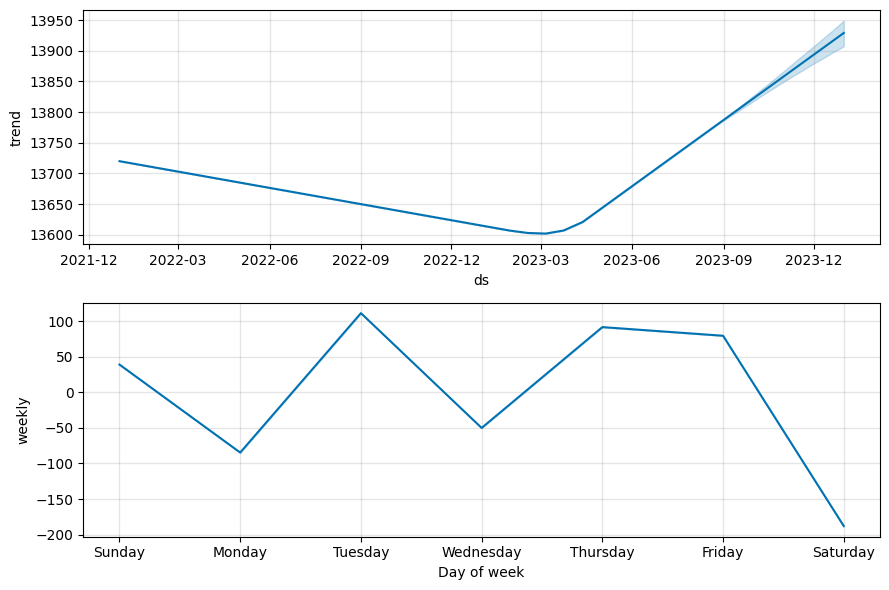

In [69]:
prophet_model.plot_components(forecast)
plt.show()

#SARIMAX

In [70]:
exog_features = [
    'Inventory Level',
    'Units Ordered',
    'Price',
    'Discount',
    'Holiday/Promotion',
    'Price Difference',
    'Weather Condition',
    'Seasonality',
    'Region',
]

In [71]:
print(df[exog_features].dtypes)

Inventory Level        int64
Units Ordered          int64
Price                float64
Discount               int64
Holiday/Promotion      int64
Price Difference     float64
Weather Condition     object
Seasonality           object
Region                object
dtype: object


In [72]:
daily_exog_numeric = df.groupby('Date').agg({
    'Inventory Level': 'mean',
    'Units Ordered': 'mean',
    'Price': 'mean',
    'Discount': 'mean',
    'Holiday/Promotion': 'mean',
    'Price Difference': 'mean'
})

daily_exog_numeric.head()

,Inventory Level,Units Ordered,Price,Discount,Holiday/Promotion,Price Difference
Date,,,,,,
2022-01-01,284.24,109.21,57.5157,10.65,0.52,0.6674
2022-01-02,272.50,107.70,60.6365,9.80,0.46,-0.3994
2022-01-03,272.69,110.96,56.7993,8.85,0.46,0.0820
2022-01-04,275.88,115.72,52.9930,10.60,0.53,-0.1777
2022-01-05,286.80,109.19,55.9958,10.40,0.45,0.0468


In [73]:
weather_daily = pd.crosstab(
    df['Date'],
    df['Weather Condition'],
    normalize='index'
)

weather_daily.head()

Weather Condition,Cloudy,Rainy,Snowy,Sunny
Date,,,,
2022-01-01,0.30,0.24,0.22,0.24
2022-01-02,0.30,0.22,0.24,0.24
2022-01-03,0.27,0.26,0.25,0.22
2022-01-04,0.27,0.23,0.20,0.30
2022-01-05,0.26,0.30,0.26,0.18


In [74]:
seasonality_daily = pd.crosstab(
    df['Date'],
    df['Seasonality'],
    normalize='index'
)

seasonality_daily.head()

Seasonality,Autumn,Spring,Summer,Winter
Date,,,,
2022-01-01,0.17,0.30,0.24,0.29
2022-01-02,0.31,0.34,0.19,0.16
2022-01-03,0.26,0.24,0.19,0.31
2022-01-04,0.19,0.25,0.28,0.28
2022-01-05,0.26,0.28,0.26,0.20


In [75]:
region_daily = pd.crosstab(
    df['Date'],
    df['Region'],
    normalize='index'
)

region_daily.head()

Region,East,North,South,West
Date,,,,
2022-01-01,0.17,0.20,0.28,0.35
2022-01-02,0.30,0.21,0.17,0.32
2022-01-03,0.20,0.27,0.29,0.24
2022-01-04,0.23,0.30,0.17,0.30
2022-01-05,0.28,0.21,0.23,0.28


In [76]:
weather_daily = weather_daily.drop(columns=['Cloudy'])
seasonality_daily = seasonality_daily.drop(columns=['Autumn'])
region_daily = region_daily.drop(columns=['East'])

In [77]:
daily_exog = daily_exog_numeric.join([
    weather_daily,
    seasonality_daily,
    region_daily
])

daily_exog.head()

,Inventory Level,Units Ordered,Price,Discount,Holiday/Promotion,Price Difference,Rainy,Snowy,Sunny,Spring,Summer,Winter,North,South,West
Date,,,,,,,,,,,,,,,
2022-01-01,284.24,109.21,57.5157,10.65,0.52,0.6674,0.24,0.22,0.24,0.30,0.24,0.29,0.20,0.28,0.35
2022-01-02,272.50,107.70,60.6365,9.80,0.46,-0.3994,0.22,0.24,0.24,0.34,0.19,0.16,0.21,0.17,0.32
2022-01-03,272.69,110.96,56.7993,8.85,0.46,0.0820,0.26,0.25,0.22,0.24,0.19,0.31,0.27,0.29,0.24
2022-01-04,275.88,115.72,52.9930,10.60,0.53,-0.1777,0.23,0.20,0.30,0.25,0.28,0.28,0.30,0.17,0.30
2022-01-05,286.80,109.19,55.9958,10.40,0.45,0.0468,0.30,0.26,0.18,0.28,0.26,0.20,0.21,0.23,0.28


In [78]:
daily_exog = daily_exog.loc[ts.index]

daily_exog.shape, ts.shape

((730, 15), (730,))

In [79]:
train_size = int(len(ts) * 0.8)

y_train = ts.iloc[:train_size]
y_test = ts.iloc[train_size:]

X_train = daily_exog.iloc[:train_size]
X_test = daily_exog.iloc[train_size:]

y_train.shape, y_test.shape, X_train.shape, X_test.shape

((584,), (146,), (584, 15), (146, 15))

In [80]:


sarimax_model = SARIMAX(
    y_train,
    exog=X_train,
    order=(0, 0, 0),
    seasonal_order=(0, 0, 0, 0),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarimax_result = sarimax_model.fit(disp=False)

print(sarimax_result.summary())

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:             Units Sold   No. Observations:                  584
Model:                        SARIMAX   Log Likelihood               -4736.825
Date:                Tue, 20 Oct 2026   AIC                           9505.650
Time:                        18:09:38   BIC                           9575.541
Sample:                    01-01-2022   HQIC                          9532.892
                         - 08-07-2023                                         
Covariance Type:                  opg                                         
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
Inventory Level      48.9215      2.360     20.733      0.000      44.297      53.546
Units Ordered        -7.8503      5.758     -1.363      0.173     -19.136       3.435
Price                 0.

In [81]:
sarimax_forecast = sarimax_result.get_forecast(
    steps=len(y_test),
    exog=X_test
)

y_pred_sarimax = sarimax_forecast.predicted_mean

y_pred_sarimax.head()

,predicted_mean
2023-08-08,13666.606593
2023-08-09,13454.874757
2023-08-10,12926.100902
2023-08-11,13729.548091
2023-08-12,13004.200852


In [82]:


mae_sarimax = mean_absolute_error(y_test, y_pred_sarimax)
rmse_sarimax = np.sqrt(mean_squared_error(y_test, y_pred_sarimax))
mape_sarimax = np.mean(np.abs((y_test - y_pred_sarimax) / y_test)) * 100

mae_sarimax, rmse_sarimax, mape_sarimax

(648.1409685898141,
 np.float64(826.155324311267),
 np.float64(4.8085938247288595))

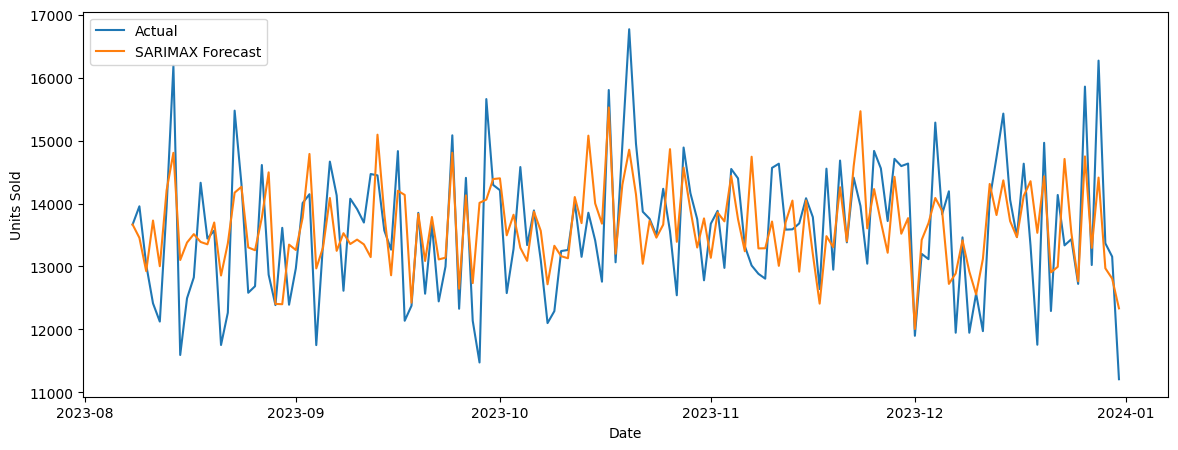

In [83]:


plt.figure(figsize=(14, 5))

plt.plot(y_test.index, y_test, label='Actual')
plt.plot(y_test.index, y_pred_sarimax, label='SARIMAX Forecast')

#plt.title('SARIMAX: Actual vs Forecast')
plt.xlabel('Date')
plt.ylabel('Units Sold')
plt.legend()
plt.show()

In [84]:
sarimax_ar1 = SARIMAX(
    y_train,
    exog=X_train,
    order=(1, 0, 0),
    seasonal_order=(0, 0, 0, 0),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarimax_ar1_result = sarimax_ar1.fit(disp=False)

print(sarimax_ar1_result.summary())

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:             Units Sold   No. Observations:                  584
Model:               SARIMAX(1, 0, 0)   Log Likelihood               -4735.043
Date:                Tue, 20 Oct 2026   AIC                           9504.085
Time:                        18:09:38   BIC                           9578.344
Sample:                    01-01-2022   HQIC                          9533.030
                         - 08-07-2023                                         
Covariance Type:                  opg                                         
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
Inventory Level      48.9091      2.384     20.516      0.000      44.237      53.582
Units Ordered        -7.9301      5.742     -1.381      0.167     -19.184       3.323
Price                 0.

In [85]:
sarimax_ar1_forecast = sarimax_ar1_result.get_forecast(
    steps=len(y_test),
    exog=X_test
)

y_pred_sarimax_ar1 = sarimax_ar1_forecast.predicted_mean

y_pred_sarimax_ar1.head()

,predicted_mean
2023-08-08,13728.634824
2023-08-09,13459.386540
2023-08-10,12926.514209
2023-08-11,13729.001797
2023-08-12,13003.673271


In [86]:
mae_sarimax_ar1 = mean_absolute_error(y_test, y_pred_sarimax_ar1)
rmse_sarimax_ar1 = np.sqrt(mean_squared_error(y_test, y_pred_sarimax_ar1))
mape_sarimax_ar1 = np.mean(
    np.abs((y_test - y_pred_sarimax_ar1) / y_test)
) * 100

mae_sarimax_ar1, rmse_sarimax_ar1, mape_sarimax_ar1

(648.5290539663688,
 np.float64(826.0983545053491),
 np.float64(4.8113967256680015))

#Model Comparison

In [87]:
model_comparison = pd.DataFrame({
    'Model': [
        'Naive',
        'ARIMA(0,0,0)',
        'SARIMA(0,0,0)(1,0,0,7)',
        'Prophet',
        'SARIMAX(0,0,0)'
    ],
    'MAE': [
        naive_mae,
        845.69,
        sarima_mae,
        prophet_mae,
        mae_sarimax
    ],
    'RMSE': [
        naive_rmse,
        1054.17,
        sarima_rmse,
        prophet_rmse,
        rmse_sarimax
    ]
})

model_comparison

,Model,MAE,RMSE
0,Naive,1171.452055,1479.497416
1,"ARIMA(0,0,0)",845.690000,1054.170000
2,"SARIMA(0,0,0)(1,0,0,7)",1152.642521,1441.969847
3,Prophet,875.363420,1085.777285
4,"SARIMAX(0,0,0)",648.140969,826.155324


#Final Findings and Conclusions
- Sales showed limited time-based patterns.
- ARIMA improved on the naive model, while SARIMA and Prophet showed little additional benefit. SARIMAX performed best, with Inventory Level as the strongest significant predictor.
- Business Recommendation: Use inventory levels in demand forecasting and replenishment planning.